In [2]:
import pandas as pd
import numpy as np
from sklearn.impute import KNNImputer
from datetime import datetime

# Read the CSV file into a DataFrame
df = pd.read_csv("Nashville Accidents Jan 2018 - Apl 2025.csv")

# 1. Initial Data Inspection

print("Initial Data Shape:", df.shape)
print("\nMissing Values Before Cleaning:")
print(df.isnull().sum().sort_values(ascending=False))

Initial Data Shape: (216117, 27)

Missing Values Before Cleaning:
Property Damage               198477
Weather Description            21464
Weather                        21464
HarmfulDescriptions            21435
HarmfulCodes                   19245
Illumination Description       13460
IlluACCIDEmination             13456
Collision Type                 12974
Collision Type Description     12974
Street Address                   236
Zip Code                         143
Precinct                         110
RPA                              105
Reporting Officer                 15
Hit and Run                       14
State                              4
City                               4
Number of Motor Vehicles           4
Number of Fatalities               3
Number of Injuries                 3
x                                  2
y                                  2
Long                               2
Lat                                2
ObjectId                           0
Date and 

In [1]:

# 2. Handling Missing Values

# Remove columns with too many missing values (threshold: 70% non-null)
threshold = len(df) * 0.3
df = df.dropna(thresh=threshold, axis=1)

# Remove rows with all values missing
df = df.dropna(how='all')

# Impute missing values
for col in df.columns:
    # For numeric columns
    if df[col].dtype in ['int64', 'float64']:
        # Use median for skewed distributions
        if df[col].skew() > 1:
            df[col].fillna(df[col].median(), inplace=True)
        else:
            df[col].fillna(df[col].mean(), inplace=True)
    # For categorical columns
    elif df[col].dtype == 'object':
        df[col].fillna(df[col].mode()[0], inplace=True)

NameError: name 'df' is not defined

In [5]:
# Advanced imputation for selected numeric columns using KNN
numeric_cols = df.select_dtypes(include=['int64', 'float64']).columns
if len(numeric_cols) > 0:
    imputer = KNNImputer(n_neighbors=5)
    df[numeric_cols] = imputer.fit_transform(df[numeric_cols])

In [6]:

# 3. Removing Duplicates

# Remove exact duplicates
df = df.drop_duplicates()

# Remove near-duplicates based on key columns (adjust as needed)
key_columns = ['Date and Time', 'Street Address', 'Number of Motor Vehicles']
df = df.drop_duplicates(subset=key_columns, keep='first')

In [7]:

# 4. Fixing Inconsistent Data Entries

# Standardize categorical values
categorical_cols = ['Property Damage', 'Hit and Run', 'Weather Description', 'Illumination Description']
for col in categorical_cols:
    if col in df.columns:
        df[col] = df[col].str.strip().str.lower()
        df[col] = df[col].replace({
            'yes': 'y',
            'no': 'n',
            'clear': 'no adverse conditions',
            'daylight': 'daylight'
        })

In [8]:

# 5. Correcting Data Types

# Convert date/time columns
if 'Date and Time' in df.columns:
    df['Date and Time'] = pd.to_datetime(df['Date and Time'], errors='coerce')
    # Extract date and time components
    df['Date'] = df['Date and Time'].dt.date
    df['Time'] = df['Date and Time'].dt.time
    df['Year'] = df['Date and Time'].dt.year
    df['Month'] = df['Date and Time'].dt.month
    df['Day'] = df['Date and Time'].dt.day
    df['Hour'] = df['Date and Time'].dt.hour
    df['Day_of_week'] = df['Date and Time'].dt.day_name()

# Convert numeric columns stored as strings
numeric_cols_to_convert = ['Number of Motor Vehicles', 'Number of Injuries', 'Number of Fatalities']
for col in numeric_cols_to_convert:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors='coerce').fillna(0).astype(int)

In [ ]:

# 6. Final Data Inspection

print("\nData Shape After Cleaning:", df.shape) #398 rows deleted, 6 columns created
print("\nMissing Values After Cleaning:")
print(df.isnull().sum().sort_values(ascending=False))
print("\nData Types After Cleaning:")
print(df.dtypes)

# Save cleaned data to new CSV
df.to_csv('Nashville_Accidents_Cleaned.csv', index=False)
print("\nCleaned data saved to 'Nashville_Accidents_Cleaned.csv'")

In [11]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler, StandardScaler, LabelEncoder, OneHotEncoder
from scipy import stats
from sklearn.preprocessing import KBinsDiscretizer


# 1. Normalization/Scaling


# Select numeric columns that would benefit from scaling
numeric_cols = ['Number of Motor Vehicles', 'Number of Injuries', 'Number of Fatalities', 'Lat', 'Long']

# Min-Max Scaling (normalize to 0-1 range)
if all(col in df.columns for col in numeric_cols):
    minmax_scaler = MinMaxScaler()
    df[numeric_cols] = minmax_scaler.fit_transform(df[numeric_cols])
    df = df.rename(columns={col: f"{col}_scaled" for col in numeric_cols})

In [12]:

# 2. Encoding Categorical Variables


# One-hot encoding for low-cardinality categorical columns
categorical_cols = ['Hit and Run', 'Property Damage', 'Collision Type Description', 'Weather Description']
for col in categorical_cols:
    if col in df.columns and df[col].nunique() < 10:  # Only for columns with <10 unique values
        df = pd.concat([df, pd.get_dummies(df[col], prefix=col)], axis=1)

# Label encoding for ordinal categories or high-cardinality columns
label_cols = ['Precinct', 'City']
for col in label_cols:
    if col in df.columns:
        le = LabelEncoder()
        df[f"{col}_encoded"] = le.fit_transform(df[col])

In [13]:

# 3. Handling Skewed Distributions


# Log transform for positively skewed numeric columns
skewed_cols = ['Number of Injuries', 'Number of Fatalities']
for col in skewed_cols:
    if col in df.columns and df[col].skew() > 1:  # Only if significantly skewed
        df[f"log_{col}"] = np.log1p(df[col])  # log1p handles zeros

In [14]:

# 4. Discretization/Binning


# Time-based binning
if 'Hour' in df.columns:
    df['Time_of_Day'] = pd.cut(df['Hour'],
                              bins=[0, 6, 12, 18, 24],
                              labels=['Night', 'Morning', 'Afternoon', 'Evening'],
                              include_lowest=True)

# Severity binning based on injuries
if 'Number of Injuries' in df.columns:
    df['Severity_Level'] = pd.cut(df['Number of Injuries'],
                                bins=[-1, 0, 1, 3, np.inf],
                                labels=['No injury', 'Minor', 'Moderate', 'Severe'])

# Geographic binning (latitude/longitude)
if all(col in df.columns for col in ['Lat', 'Long']):
    discretizer = KBinsDiscretizer(n_bins=5, encode='ordinal', strategy='quantile')
    df[['Lat_bin', 'Long_bin']] = discretizer.fit_transform(df[['Lat', 'Long']]).astype(int)

In [ ]:

# 5. Save Transformed Data

df.to_csv('Nashville_Accidents_Transformed.csv', index=False)
print("Data transformation complete. Saved to 'Nashville_Accidents_Transformed.csv'")
print("\nTransformed columns sample:")
print(df.iloc[0][df.columns.difference(numeric_cols + categorical_cols + label_cols)].head(10))

Data transformation complete. Saved to 'Nashville_Accidents_Transformed.csv'

Transformed columns sample:
Accident Number                      2008473471.0
City_encoded                                   12
Collision Type                                4.0
Date                                   2018-07-14
Date and Time                 2018-07-14 23:00:00
Day                                            14
Day_of_week                              Saturday
HarmfulCodes                                   12
HarmfulDescriptions    MOTOR VEHICLE IN TRANSPORT
Hit and Run_n                                True
Name: 0, dtype: object


Outliers in Number of Motor Vehicles_scaled: 2981


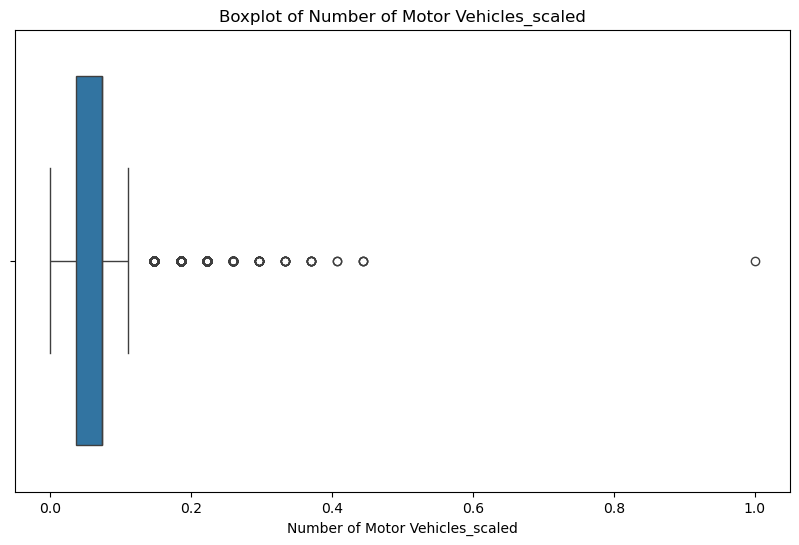

Outliers in Number of Injuries_scaled: 5124


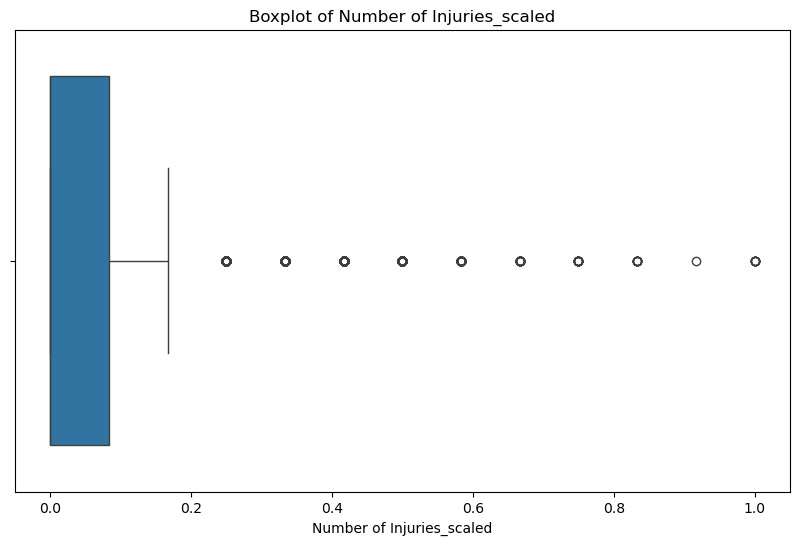

In [15]:
#3) Handling Outliers using Winsorization

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the data
df = pd.read_csv('Nashville_Accidents_Transformed.csv')

# Function to detect outliers using IQR method
def detect_outliers_iqr(data, column):
    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = data[(data[column] < lower_bound) | (data[column] > upper_bound)]
    return outliers

# Function to visualize outliers
def plot_outliers(data, column):
    plt.figure(figsize=(10, 6))
    sns.boxplot(x=data[column])
    plt.title(f'Boxplot of {column}')
    plt.show()

# Columns to check for outliers
numeric_columns = ['Number of Motor Vehicles_scaled', 'Number of Injuries_scaled'] 
                  

# Detect and visualize outliers for each numeric column
for col in numeric_columns:
    outliers = detect_outliers_iqr(df, col)
    print(f"Outliers in {col}: {len(outliers)}")
    plot_outliers(df, col)


df_original = df[numeric_columns].copy()

In [16]:
def treat_outliers_winsorization(data, column):
    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    # Cap the outliers
    data[column] = np.where(data[column] < lower_bound, lower_bound, 
                           np.where(data[column] > upper_bound, upper_bound, data[column]))
    return data


for col in numeric_columns:
    # Outliers before treatment
    outliers_before = detect_outliers_iqr(df, col)
    num_outliers_before = len(outliers_before)

    # Store original values to compare later
    original_values = df[col].copy()

    # Apply treatment
    df = treat_outliers_winsorization(df, col)

    # Outliers after treatment
    outliers_after = detect_outliers_iqr(df, col)
    num_outliers_after = len(outliers_after)


    # Output
    print(f"{col}:")
    print(f"  Number of outliers before treatment: {num_outliers_before}")
    print(f"  Number of outliers after treatment:  {num_outliers_after}")

Number of Motor Vehicles_scaled:
  Number of outliers before treatment: 2981
  Number of outliers after treatment:  0
Number of Injuries_scaled:
  Number of outliers before treatment: 5124
  Number of outliers after treatment:  0


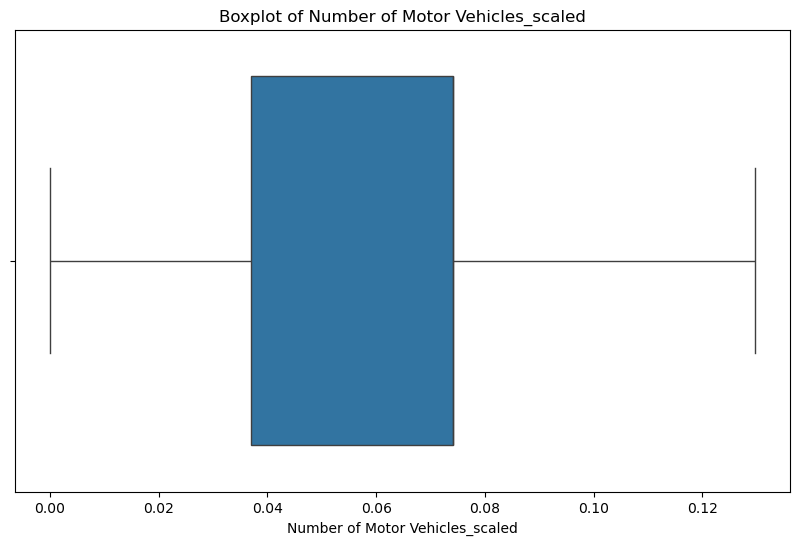

Statistics for Number of Motor Vehicles_scaled:
count    215719.000000
mean          0.063063
std           0.029073
min           0.000000
25%           0.037037
50%           0.074074
75%           0.074074
max           0.129630
Name: Number of Motor Vehicles_scaled, dtype: float64




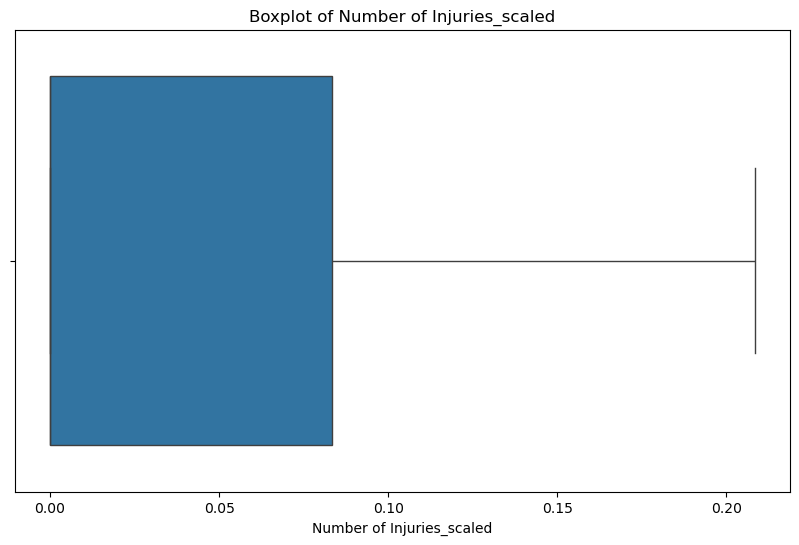

Statistics for Number of Injuries_scaled:
count    215719.000000
mean          0.032083
std           0.055162
min           0.000000
25%           0.000000
50%           0.000000
75%           0.083333
max           0.208333
Name: Number of Injuries_scaled, dtype: float64




In [17]:
for col in numeric_columns:
    plot_outliers(df, col)
    print(f"Statistics for {col}:")
    print(df[col].describe())
    print("\n")

In [ ]:
df.to_csv('Nashville_Accidents_OutliersTreated.csv', index=False)
print("\nOutlier treatment complete. Saved to 'Nashville_Accidents_OutliersTreated.csv'")